# 4. POC : trouver ses quartiers

L'utilisateur dit ce qui compte pour lui (importance de 0 à 3 pour chaque critère), son budget, le nombre de pièces qu'il cherche et les lieux qu'il veut avoir près de chez lui. Deux modes, comme dans l'extension Chrome :
1. **Recommandation** : les k IRIS les plus proches de ce qu'il cherche (k-NN du notebook 3) ;
2. **Adresse** : pour une adresse donnée (une annonce par exemple), à quel point son quartier correspond à ses critères.

À la fin, on exporte les données pour l'extension (`../extension_créer_par_IA/`).

In [9]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import ipywidgets as widgets
import requests
from shapely.geometry import Point
from IPython.display import display
from sklearn.neighbors import NearestNeighbors

In [10]:
SAVE_DIR = "../save/"
EXTENSION_DIR = "../extension_créer_par_IA/"
L93 = 2154
SIMPLIFICATION_M = 5

COLUMNS_INFO = ['nom_iris', 'nom_quartier', 'nom_com']
COLUMNS_BUDGET = ['prix_m2_median', 'prix_m2_median_1p', 'prix_m2_median_2p', 'prix_m2_median_3p', 'prix_m2_median_4p', 'prix_m2_median_5p_plus',
                  'loyer_ref_m2', 'loyer_ref_m2_1p', 'loyer_ref_m2_2p', 'loyer_ref_m2_3p', 'loyer_ref_m2_4p',
                  'loyer_majore_m2', 'loyer_majore_m2_1p', 'loyer_majore_m2_2p', 'loyer_majore_m2_3p', 'loyer_majore_m2_4p']

In [11]:
iris = gpd.read_parquet(SAVE_DIR + "iris_features.parquet").set_index("code_iris")
scores = pd.read_parquet(SAVE_DIR + "iris_scores.parquet")
CRITERES = list(scores.columns.drop("type_quartier"))
LIEUX = [col[5:-2] for col in iris.columns if col.startswith("dist_")]
print(len(scores), "IRIS d'habitat")
print("Critères :", CRITERES)
print("Lieux :", LIEUX)

861 IRIS d'habitat
Critères : ['transports', 'accessibilite_pmr', 'ecoles', 'verdure', 'calme', 'commerces', 'sante', 'sorties', 'services_publics', 'sport_culture', 'voiture', 'grands_logements', 'quartier_jeune']
Lieux : ['espace_vert_visitable', 'velib', 'tram', 'metro', 'train', 'bus', 'etablissement_scolaire', 'ecole', 'college', 'lycee', 'supermarche', 'superette', 'boulangerie', 'boucherie_poissonnerie', 'primeur', 'pharmacie', 'medecin', 'dentiste', 'creche', 'salle_sport', 'cinema', 'librairie', 'bureau_poste', 'pressing_laverie', 'veterinaire']


Ce que contient chaque critère (détail dans le notebook 3) :

| Critère | Variables |
|---|---|
| transports | distance métro, RER/train, tram, bus, Vélib', passages par jour, nombre de lignes (GTFS) |
| accessibilite_pmr | part des quais accessibles en fauteuil (GTFS) |
| ecoles | distance crèche, école, collège, lycée, IPS école et lycée, réussite et valeur ajoutée du collège |
| verdure | part de surface verte, distance au parc, densité d'arbres, hauteur des arbres, part d'arbres adultes |
| calme | indice bruit, indice air, part en point noir air-bruit |
| commerces | distance supermarché, supérette, boulangerie, boucherie, primeur, pressing, marchés, densité de commerces |
| sante | distance pharmacie, médecin, dentiste, densité santé |
| sorties | densité restaurants et bars |
| services_publics | densité lieux municipaux, distance bureau de poste |
| sport_culture | distance salle de sport, cinéma, librairie, densité bibliothèques, gymnases, terrains de sport |
| voiture | ménages avec parking, densité de places, places payant mixte (résidents) |
| grands_logements | part de 5 pièces et plus, de 100 m² et plus, suroccupation |
| quartier_jeune | part des 15-24 ans et des étudiants |

Le budget n'est pas un critère mais un filtre. Si l'utilisateur donne un nombre de pièces, on compare au prix et au loyer de ce type de logement dans l'IRIS.

## Le k-NN et le score de correspondance

Chaque IRIS d'habitat a un score entre 0 et 1 par critère. Le quartier idéal vaut 1 partout. On multiplie les scores par les poids de l'utilisateur et on cherche les k IRIS les plus proches du quartier idéal.

La correspondance d'un IRIS se lit sur la même distance : 100 % = le quartier idéal, 0 % = le pire possible (0 sur tous les critères demandés). Le rang dit où se place l'IRIS parmi les 861.

In [12]:
def colonnes_budget(pieces):
    if not pieces:
        return "prix_m2_median", "loyer_ref_m2"
    prix = "prix_m2_median_5p_plus" if pieces >= 5 else f"prix_m2_median_{pieces}p"
    return prix, f"loyer_ref_m2_{min(pieces, 4)}p"


def distance_ideal(poids):
    poids = pd.Series(poids).reindex(CRITERES, fill_value=0)
    distances = np.sqrt((((1 - scores[CRITERES]) * poids) ** 2).sum(axis=1))
    correspondance = 100 * (1 - distances / np.sqrt((poids ** 2).sum()))
    return correspondance.round(1), distances.rank(method="min").astype(int)


def recommander(poids, prix_m2_max=None, loyer_m2_max=None, distances_max={}, pieces=None, k=10):
    poids = pd.Series(poids).reindex(CRITERES, fill_value=0)
    col_prix, col_loyer = colonnes_budget(pieces)
    infos = iris.loc[scores.index]
    garder = pd.Series(True, index=scores.index)
    if prix_m2_max:
        garder &= infos[col_prix] <= prix_m2_max
    if loyer_m2_max:
        garder &= infos[col_loyer] <= loyer_m2_max
    for lieu, distance_max in distances_max.items():
        garder &= infos[f"dist_{lieu}_m"] <= distance_max

    candidats = scores.loc[garder, CRITERES]
    if candidats.empty:
        return None
    knn = NearestNeighbors(n_neighbors=min(k, len(candidats))).fit(candidats * poids)
    distances, positions = knn.kneighbors(poids.to_frame().T)

    criteres_choisis = list(poids[poids > 0].index)
    reco = infos.loc[candidats.index[positions[0]], COLUMNS_INFO + [col_prix, col_loyer] + [f"dist_{l}_m" for l in distances_max]]
    reco = reco.join(scores[criteres_choisis + ["type_quartier"]])
    reco.insert(0, "rang", range(1, len(reco) + 1))
    reco.insert(1, "correspondance_%", 100 * (1 - distances[0] / np.sqrt((poids ** 2).sum())))
    return reco.round(2)


def evaluer_adresse(adresse, poids, prix_m2_max=None, loyer_m2_max=None, distances_max={}, pieces=None):
    reponse = requests.get("https://api-adresse.data.gouv.fr/search/", params={"q": adresse, "limit": 1}, timeout=10).json()
    if not reponse["features"]:
        return None
    point = Point(reponse["features"][0]["geometry"]["coordinates"])
    trouve = iris[iris.contains(point)]
    if trouve.empty:
        return None

    code_iris = trouve.index[0]
    quartier = iris.loc[code_iris]
    resultat = {"adresse": reponse["features"][0]["properties"]["label"], "code_iris": code_iris,
                "nom_iris": quartier["nom_iris"], "nom_quartier": quartier["nom_quartier"]}
    if code_iris not in scores.index:
        resultat["correspondance_%"] = "IRIS sans logements"
        return pd.Series(resultat)

    correspondance, rang = distance_ideal(poids)
    resultat["correspondance_%"] = correspondance[code_iris]
    resultat["rang"] = f"{rang[code_iris]} / {len(scores)}"
    resultat.update(scores.loc[code_iris, [c for c in CRITERES if poids.get(c, 0) > 0]].round(2).to_dict())

    col_prix, col_loyer = colonnes_budget(pieces)
    if prix_m2_max:
        resultat[f"{col_prix} <= {prix_m2_max}"] = quartier[col_prix] <= prix_m2_max
    if loyer_m2_max:
        resultat[f"{col_loyer} <= {loyer_m2_max}"] = quartier[col_loyer] <= loyer_m2_max
    for lieu, distance_max in distances_max.items():
        resultat[f"{lieu} à moins de {distance_max} m"] = quartier[f"dist_{lieu}_m"] <= distance_max
    return pd.Series(resultat)


def carte(reco):
    fig, ax = plt.subplots(figsize=(9, 6))
    iris.plot(ax=ax, color="#e5e5e5", edgecolor="white", linewidth=0.2)
    iris.loc[reco.index, ["geometry"]].join(reco["correspondance_%"]).plot(ax=ax, column="correspondance_%", cmap="RdYlGn", vmin=0, vmax=100, legend=True)
    for code_iris, rang in reco["rang"].items():
        point = iris.loc[code_iris].geometry.representative_point()
        ax.annotate(str(rang), (point.x, point.y), fontsize=8, ha="center", fontweight="bold")
    ax.set_axis_off()
    plt.show()

## 1. Mode recommandation

Une famille qui cherche un 4 pièces pour 10 500 €/m² maximum : calme, verdure (parcs et arbres), grands logements, bonnes écoles, avec un supermarché à moins de 400 m et une crèche à moins de 300 m. Changer les valeurs pour tester un autre profil.

,rang,correspondance_%,nom_iris,nom_quartier,nom_com,prix_m2_median_4p,loyer_ref_m2_4p,dist_supermarche_m,dist_creche_m,transports,ecoles,verdure,calme,grands_logements,type_quartier
code_iris,,,,,,,,,,,,,,,
751155916,1,71.71,Grenelle 16,Grenelle,Paris 15e Arrondissement,9727.0,24.50,103.0,65.0,0.54,0.50,0.72,0.92,0.79,3 : grands_logements + quartier_jeune
751156008,2,70.85,Javel 8,Javel 15Art,Paris 15e Arrondissement,9727.0,24.50,149.0,96.0,0.56,0.50,0.77,0.90,0.63,3 : grands_logements + quartier_jeune
751145610,3,70.25,Plaisance 10,Plaisance,Paris 14e Arrondissement,9811.0,21.52,99.0,21.0,0.65,0.58,0.68,0.82,0.71,1 : quartier_jeune + sante
751155903,4,68.25,Grenelle 3,Grenelle,Paris 15e Arrondissement,9727.0,24.50,154.0,117.0,0.52,0.65,0.68,0.91,0.49,2 : calme + services_publics
751156019,5,67.90,Javel 19,Javel 15Art,Paris 15e Arrondissement,9727.0,24.50,144.0,47.0,0.56,0.74,0.57,0.95,0.60,2 : calme + services_publics
751156010,6,66.59,Javel 10,Javel 15Art,Paris 15e Arrondissement,9727.0,24.50,92.0,73.0,0.57,0.50,0.62,0.84,0.72,3 : grands_logements + quartier_jeune
751135020,7,66.50,Gare 20,Gare,Paris 13e Arrondissement,8310.0,18.00,192.0,45.0,0.32,0.65,0.60,0.97,0.60,2 : calme + services_publics
751156003,8,65.60,Javel 3,Javel 15Art,Paris 15e Arrondissement,9727.0,24.50,115.0,141.0,0.55,0.32,0.72,0.92,0.69,3 : grands_logements + quartier_jeune
751197607,9,65.51,Combat 7,Combat,Paris 19e Arrondissement,8430.0,19.98,276.0,86.0,0.18,0.56,0.84,0.63,0.73,2 : calme + services_publics


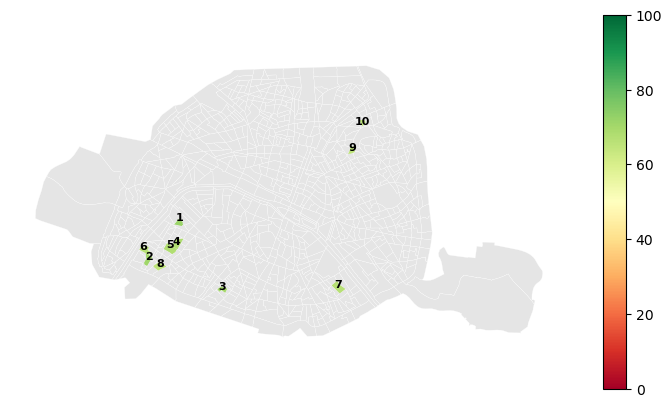

In [13]:
MES_POIDS = {"calme": 3, "verdure": 3, "grands_logements": 2, "ecoles": 2, "transports": 1}
PRIX_M2_MAX = 10500
LOYER_M2_MAX = None
PIECES = 4
DISTANCES_MAX = {"supermarche": 400, "creche": 300}
K = 10

reco = recommander(MES_POIDS, PRIX_M2_MAX, LOYER_M2_MAX, DISTANCES_MAX, PIECES, K)
display(reco)
carte(reco)

Un jeune actif qui loue un 2 pièces, veut sortir, faire du sport et être bien desservi, avec un métro à moins de 300 m :

,rang,correspondance_%,nom_iris,nom_quartier,nom_com,prix_m2_median_2p,loyer_ref_m2_2p,dist_metro_m,transports,sorties,sport_culture,quartier_jeune,type_quartier
code_iris,,,,,,,,,,,,,
751051803,1,77.35,Jardin des Plantes 3,Jardin-des-Plantes,Paris 5e Arrondissement,10808.0,25.15,157.0,0.73,0.85,0.70,0.93,1 : quartier_jeune + sante
751124808,2,75.90,Quinze-Vingts 8,Quinze-Vingts,Paris 12e Arrondissement,9529.0,25.05,232.0,0.74,0.92,0.61,0.72,1 : quartier_jeune + sante
751103906,3,74.10,Porte Saint-Martin 6,Porte-Saint-Martin,Paris 10e Arrondissement,10000.0,25.05,77.0,0.75,0.88,0.68,0.36,0 : sorties + commerces
751176805,4,72.91,Épinettes 5,Epinettes,Paris 17e Arrondissement,9637.0,25.05,60.0,0.79,0.98,0.56,0.27,0 : sorties + commerces
751197522,5,71.06,Amérique 22,Amérique,Paris 19e Arrondissement,7917.0,21.85,199.0,0.61,0.88,0.78,0.52,0 : sorties + commerces
751114106,6,70.32,Folie Méricourt 6,Folie-Méricourt,Paris 11e Arrondissement,9286.0,25.05,64.0,0.65,0.97,0.66,0.32,0 : sorties + commerces
751104004,7,70.30,Hôpital Saint-Louis 4,Hôpital-Saint-Louis,Paris 10e Arrondissement,9623.0,25.05,146.0,0.59,0.90,0.70,0.72,0 : sorties + commerces
751103904,8,70.11,Porte Saint-Martin 4,Porte-Saint-Martin,Paris 10e Arrondissement,10142.0,25.05,174.0,0.64,0.83,0.68,0.50,0 : sorties + commerces
751176701,9,68.91,Batignolles 1,Batignolles,Paris 17e Arrondissement,11110.0,25.15,159.0,0.66,0.93,0.63,0.21,0 : sorties + commerces


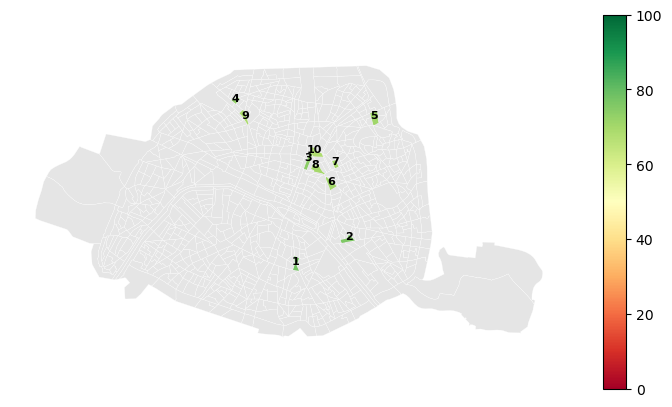

In [14]:
reco = recommander({"sorties": 3, "transports": 3, "sport_culture": 2, "quartier_jeune": 1}, loyer_m2_max=26,
                   distances_max={"metro": 300}, pieces=2)
display(reco)
carte(reco)

Une personne en fauteuil roulant qui veut des quais accessibles, des services de santé et du calme :

,rang,correspondance_%,nom_iris,nom_quartier,nom_com,prix_m2_median,loyer_ref_m2,dist_pharmacie_m,accessibilite_pmr,calme,commerces,sante,type_quartier
code_iris,,,,,,,,,,,,,
751166216,1,79.47,Muette 16,Muette,Paris 16e Arrondissement,12084.0,28.14,63.0,0.77,0.80,0.49,0.92,1 : quartier_jeune + sante
751020802,2,79.40,Bonne Nouvelle 2,Bonne-Nouvelle,Paris 2e Arrondissement,10676.0,27.54,66.0,0.77,0.74,0.78,0.86,5 : sorties + accessibilite_pmr
751020701,3,78.43,Mail 1,Mail,Paris 2e Arrondissement,12115.0,27.54,107.0,0.77,0.70,0.74,0.87,5 : sorties + accessibilite_pmr
751166217,4,78.41,Muette 17,Muette,Paris 16e Arrondissement,11782.0,28.14,89.0,0.77,0.89,0.41,0.85,3 : grands_logements + quartier_jeune
751134906,5,77.74,Salpêtrière 6,Salpêtrière,Paris 13e Arrondissement,9356.0,25.22,132.0,0.77,0.81,0.51,0.82,1 : quartier_jeune + sante
751166214,6,77.55,Muette 14,Muette,Paris 16e Arrondissement,11233.0,28.14,57.0,0.77,0.70,0.48,0.93,1 : quartier_jeune + sante
751124605,7,77.48,Picpus 5,Picpus,Paris 12e Arrondissement,8733.0,24.14,73.0,0.77,0.74,0.76,0.80,5 : sorties + accessibilite_pmr
751166204,8,76.63,Muette 4,Muette,Paris 16e Arrondissement,11486.0,28.14,75.0,0.77,0.84,0.41,0.81,3 : grands_logements + quartier_jeune
751145509,9,76.24,Petit Montrouge 9,Petit-Montrouge,Paris 14e Arrondissement,9186.0,25.22,53.0,0.77,0.71,0.78,0.78,1 : quartier_jeune + sante


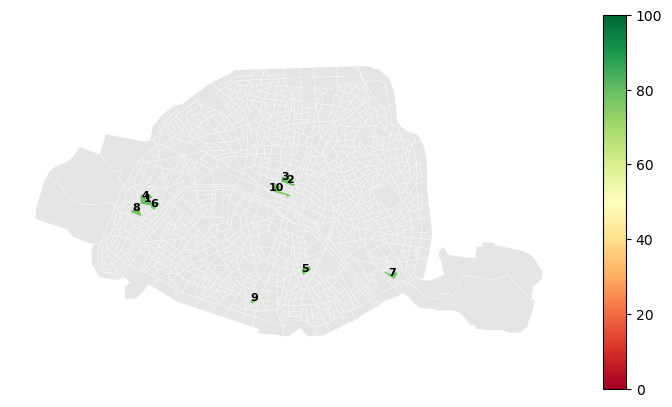

In [15]:
reco = recommander({"accessibilite_pmr": 3, "sante": 3, "calme": 2, "commerces": 1}, distances_max={"pharmacie": 300})
display(reco)
carte(reco)

## 2. Mode adresse

La famille du début regarde des annonces. Pour chaque adresse, on dit à quel point le quartier correspond à ses critères, son rang parmi les 861 IRIS d'habitat, et si le budget et les distances sont respectés.

In [16]:
ADRESSES = ["12 rue de la Roquette 75011 Paris", "20 rue de Javel 75015 Paris", "5 rue de la Convention 75015 Paris",
            "8 rue Mouffetard 75005 Paris"]

evaluations = [evaluer_adresse(a, MES_POIDS, PRIX_M2_MAX, LOYER_M2_MAX, DISTANCES_MAX, PIECES) for a in ADRESSES]
display(pd.DataFrame([e for e in evaluations if e is not None]).set_index("adresse").T)

adresse,12 Rue de la Roquette 75011 Paris,20 Rue de Javel 75015 Paris,5 Rue de la Convention 75015 Paris,8 Rue Mouffetard 75005 Paris
code_iris,751114311,751156014,751156013,751052001
nom_iris,Roquette 11,Javel 14,Javel 13,Sorbonne 1
nom_quartier,Roquette,Javel 15Art,Javel 15Art,Sorbonne
correspondance_%,29.8,45.3,50.4,52.5
rang,842 / 861,488 / 861,308 / 861,250 / 861
transports,0.45,0.63,0.49,0.48
ecoles,0.48,0.56,0.61,0.67
verdure,0.11,0.61,0.62,0.32
calme,0.46,0.34,0.56,0.81
grands_logements,0.25,0.32,0.18,0.52


## 3. Version interactive

Régler ses critères, puis :
- « Trouver mes quartiers » pour la liste des k meilleurs IRIS ;
- ou taper une adresse et « Évaluer l'adresse ».

Budget à 0 = pas de limite. Les lieux sélectionnés doivent être à moins de la distance choisie (Ctrl ou Cmd pour en choisir plusieurs).

In [17]:
style = {"description_width": "130px"}
curseurs = {c: widgets.IntSlider(value=0, min=0, max=3, description=c, style=style) for c in CRITERES}
prix = widgets.IntText(value=0, description="Prix max €/m²", style=style)
loyer = widgets.FloatText(value=0, description="Loyer max €/m²", style=style)
pieces = widgets.Dropdown(options=[("peu importe", 0), ("1", 1), ("2", 2), ("3", 3), ("4", 4), ("5 et +", 5)], description="Pièces", style=style)
lieux = widgets.SelectMultiple(options=LIEUX, description="Lieux proches", rows=6, style=style)
distance = widgets.IntSlider(value=300, min=100, max=1000, step=50, description="à moins de (m)", style=style)
k = widgets.IntSlider(value=10, min=1, max=30, description="k quartiers", style=style)
bouton_reco = widgets.Button(description="Trouver mes quartiers", button_style="primary")
adresse = widgets.Text(placeholder="ex. 20 rue de Javel 75015 Paris", description="Adresse", style=style)
bouton_adresse = widgets.Button(description="Évaluer l'adresse", button_style="info")
sortie = widgets.Output()


def lire_criteres():
    poids = {c: curseur.value for c, curseur in curseurs.items()}
    return poids, prix.value, loyer.value, {lieu: distance.value for lieu in lieux.value}, pieces.value


def chercher(_):
    with sortie:
        sortie.clear_output()
        poids, prix_max, loyer_max, distances_max, nb_pieces = lire_criteres()
        if sum(poids.values()) == 0:
            print("Mets au moins un critère au-dessus de 0.")
            return
        reco = recommander(poids, prix_max, loyer_max, distances_max, nb_pieces, k.value)
        if reco is None:
            print("Aucun quartier ne respecte ce budget et ces distances.")
            return
        display(reco)
        carte(reco)


def evaluer(_):
    with sortie:
        sortie.clear_output()
        poids, prix_max, loyer_max, distances_max, nb_pieces = lire_criteres()
        if sum(poids.values()) == 0:
            print("Mets au moins un critère au-dessus de 0.")
            return
        resultat = evaluer_adresse(adresse.value, poids, prix_max, loyer_max, distances_max, nb_pieces)
        if resultat is None:
            print("Adresse introuvable ou hors de Paris.")
            return
        display(resultat.to_frame("valeur"))


bouton_reco.on_click(chercher)
bouton_adresse.on_click(evaluer)
display(widgets.HBox([widgets.VBox(list(curseurs.values())),
                      widgets.VBox([prix, loyer, pieces, lieux, distance, k, bouton_reco, adresse, bouton_adresse])]), sortie)

Output()

## 4. Export pour l'extension Chrome

L'extension (`../extension_créer_par_IA/`) a les mêmes deux modes et fonctionne sans serveur. Elle a besoin, pour chaque IRIS, du contour, des prix et loyers (aussi par nombre de pièces), des distances à tous les lieux et des scores. Les contours sont simplifiés à 5 m pour que le fichier reste léger.

In [18]:
colonnes = ['code_iris'] + COLUMNS_INFO + COLUMNS_BUDGET + [f"dist_{l}_m" for l in LIEUX] + ['geometry']
quartiers = iris.reset_index()[colonnes].merge(scores.round(3), left_on="code_iris", right_index=True, how="left")
quartiers["geometry"] = quartiers.geometry.to_crs(L93).simplify(SIMPLIFICATION_M).to_crs(4326)

chemin = EXTENSION_DIR + "quartiers.geojson"
if os.path.exists(chemin):
    os.remove(chemin)
quartiers.to_file(chemin, driver="GeoJSON", COORDINATE_PRECISION=5)
print(quartiers.shape, f"{os.path.getsize(chemin) / 1e6:.1f} Mo")

(992, 60) 1.9 Mo
